# Bagging Exercises

![Bagging.png](Assets/Bagging.png)

# Цели обучения

- Установить связь между понятиями «бутстреппинга» и «агрегирования» (более известного как «баггинг») для снижения дисперсии
- Применять алгоритм «Случайного леса», который позволяет ещё больше снизить корреляцию, наблюдаемую в моделях, построенных методом баггинга

## Введение

Для выполнения заданий на этой неделе мы будем использовать данные об оттоке клиентов из телекоммуникационной отрасли, которые мы рассматривали на первой неделе. Файл данных называется `Orange_Telecom_Churn_Data.csv`.

> **Пояснение**
> Одно решающее дерево легко «переучивается» и сильно меняет ответ при небольшом изменении данных (высокая дисперсия).
> **Бутстреппинг** - это когда мы многократно берём случайную выборку *с повторениями* из обучающих данных.
> **Агрегирование** - мы обучаем по дереву на каждой такой выборке и усредняем (голосуем) их ответы.
> Вместе это называется **баггинг**. **Случайный лес** - это баггинг деревьев, где на каждом разбиении дерево видит ещё и только случайную часть признаков, поэтому деревья получаются менее похожими друг на друга.

In [1]:
from __future__ import print_function
import os
data_path = ['data']

# Библиотеки для работы с таблицами и графиками
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix

## Вопрос 1

* Импортируйте данные об оттоке клиентов, содержащиеся в файле `Orange_Telecom_Churn_Data.csv`.
* Удалите все столбцы, которые, вероятно, не будут использоваться для прогнозирования.
* Осуществите соответствующее кодирование типов данных.

> **Пояснение.**
> 1. `pd.read_csv` читает CSV-файл в таблицу (`DataFrame`).
> 2. `drop` удаляет столбцы, которые не помогают предсказывать отток: штат, код города и номер телефона (номер - это просто идентификатор клиента).
> 3. Столбцы с планами хранят текст `yes`/`no`. Модели удобнее работать с числами/булевыми значениями, поэтому заменяем `yes` → `True`, `no` → `False`.

In [2]:
# Путь к файлу: папка data + имя файла
filepath = os.sep.join(data_path + ['Orange_Telecom_Churn_Data.csv'])

# Читаем данные и смотрим первые 5 строк
data = pd.read_csv(filepath)
data.head()

,state,account_length,area_code,phone_number,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,...,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [3]:
# Удаляем столбцы, которые не нужны для прогноза
data = data.drop(['state', 'area_code', 'phone_number'], axis=1)

# Смотрим типы данных каждого столбца
data.dtypes

account_length                     int64
intl_plan                            str
voice_mail_plan                      str
number_vmail_messages              int64
total_day_minutes                float64
total_day_calls                    int64
total_day_charge                 float64
total_eve_minutes                float64
total_eve_calls                    int64
total_eve_charge                 float64
total_night_minutes              float64
total_night_calls                  int64
total_night_charge               float64
total_intl_minutes               float64
total_intl_calls                   int64
total_intl_charge                float64
number_customer_service_calls      int64
churned                             bool
dtype: object

В прогнозе ни в коем случае не должно фигурировать номер телефона. И вряд ли потребуются код города или штат, если только нет оснований полагать, что модель учитывает какой-то очень конкретный географический фактор.

In [4]:
# Столбцы с планами (в разных версиях файла называются intl_plan или int_plan)
plan_cols = [c for c in data.columns if c in ('intl_plan', 'int_plan', 'voice_mail_plan')]

# Заменяем 'yes' -> True, 'no' -> False
for col in plan_cols:
    data[col] = data[col].map({'yes': True, 'no': False})

data.dtypes

account_length                     int64
intl_plan                           bool
voice_mail_plan                     bool
number_vmail_messages              int64
total_day_minutes                float64
total_day_calls                    int64
total_day_charge                 float64
total_eve_minutes                float64
total_eve_calls                    int64
total_eve_charge                 float64
total_night_minutes              float64
total_night_calls                  int64
total_night_charge               float64
total_intl_minutes               float64
total_intl_calls                   int64
total_intl_charge                float64
number_customer_service_calls      int64
churned                             bool
dtype: object

Проанализируйте типы данных. Всё выглядит нормально, за исключением того, что `int_plan` и `voice_mail_plan` необходимо кодировать как булевы значения.

## Вопрос 2

* Проанализируйте распределение прогнозируемой переменной (`churned`).
* Разделите данные на обучающую и тестовую выборки. На основании распределения решите, следует ли использовать стратифицированное деление.
* Проанализируйте распределение предикторной переменной в обучающих и тестовых данных.

> **Пояснение.**
> - `value_counts(normalize=True)` показывает долю каждого класса. Ушедших клиентов (`True`) гораздо меньше, чем оставшихся - классы **несбалансированы**.
> - Данные делим на **обучающую** выборку (на ней модель учится) и **тестовую** (на ней проверяем качество на «новых» данных).
> - **Стратифицированное** деление сохраняет одинаковую долю классов в обеих частях. При дисбалансе классов это важно, иначе в тест может случайно попасть слишком мало ушедших клиентов.

In [5]:
# Распределение целевой переменной (доли классов)
y_col = 'churned'
data[y_col].value_counts(normalize=True)

churned
False    0.8586
True     0.1414
Name: proportion, dtype: float64

In [6]:
# Признаки (X) — все столбцы кроме churned; цель (y) — churned
feature_cols = [c for c in data.columns if c != y_col]

# Стратифицированное деление: 70% обучение, 30% тест
strat_shuff_split = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)

train_idx, test_idx = next(strat_shuff_split.split(data[feature_cols], data[y_col]))

X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, y_col]

X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, y_col]

In [7]:
# Проверяем, что доли классов в обучающей и тестовой выборках почти одинаковы
print('Обучающая выборка:')
print(y_train.value_counts(normalize=True))
print()
print('Тестовая выборка:')
print(y_test.value_counts(normalize=True))

Обучающая выборка:
churned
False    0.858571
True     0.141429
Name: proportion, dtype: float64

Тестовая выборка:
churned
False    0.858667
True     0.141333
Name: proportion, dtype: float64


Учитывая асимметрию переменной-предиктора, давайте разбиваем данные, стратифицировав значения *churned*.

## Вопрос 3

* Постройте модели «случайного леса» с различным количеством деревьев и оцените ошибку «out-of-bag» для каждой из этих моделей.
* Постройте график полученных ошибок «out-of-bag» в зависимости от количества деревьев.

*Подсказка:* поскольку изменяется только количество деревьев, можно использовать флаг `warm_start`, чтобы модель каждый раз просто добавляла новые деревья к существующей модели. Для обновления количества деревьев используйте метод `set_params`.


> **Out-of-bag (OOB) ошибка.** Каждое дерево обучается на бутстреп-выборке, и примерно треть объектов в неё не попадает. Эти «забытые» объекты можно использовать как мини-тест для этого дерева. Усреднив такие проверки по всему лесу, получаем честную оценку ошибки без отдельной тестовой выборки.
> `oob_score_` - это *точность*, поэтому ошибка = `1 - oob_score_`.
> Мы в цикле увеличиваем число деревьев и смотрим, как меняется ошибка. `warm_start=True` позволяет не обучать лес заново, а просто добавлять деревья к уже обученным.

In [8]:
# Suppress warnings about too few trees from the early models

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [9]:
# Модель случайного леса с оценкой OOB и возможностью дообучения
RF = RandomForestClassifier(oob_score=True, random_state=42, warm_start=True, n_jobs=-1)

# Разные значения количества деревьев
n_trees_list = [15, 20, 30, 40, 50, 100, 150, 200, 300, 400]

oob_list = []

for n_trees in n_trees_list:
    # Меняем число деревьев и дообучаем модель
    RF.set_params(n_estimators=n_trees)
    RF.fit(X_train, y_train)

    # OOB-ошибка = 1 - OOB-точность
    oob_error = 1 - RF.oob_score_
    oob_list.append(pd.Series({'n_trees': n_trees, 'oob': oob_error}))

rf_oob_df = pd.concat(oob_list, axis=1).T.set_index('n_trees')
rf_oob_df

,oob
n_trees,
15.0,0.059714
20.0,0.053429
30.0,0.049714
40.0,0.047429
50.0,0.049143
100.0,0.045143
150.0,0.045143
200.0,0.044857
300.0,0.044286


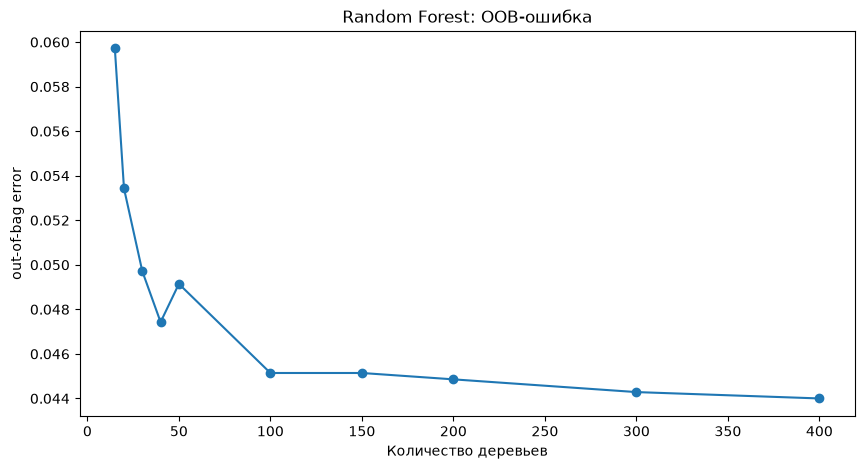

In [10]:
# График: OOB-ошибка в зависимости от числа деревьев
ax = rf_oob_df.plot(legend=False, marker='o', figsize=(10, 5))
ax.set(ylabel='out-of-bag error', xlabel='Количество деревьев', title='Random Forest: OOB-ошибка')
plt.show()

Похоже, что количество ошибок стабилизировалось на уровне 100–150 деревьев.

## Вопрос 4

* Повторите задание из вопроса 3, используя дополнительные рандомизированные деревья (`ExtraTreesClassifier`). Обратите внимание, что для этой модели параметр `bootstrap` необходимо установить в значение `True`.
* Сравните ошибки метода «out-of-bag» для двух различных типов моделей.


> `ExtraTreesClassifier` («чрезвычайно случайные деревья») похож на случайный лес, но пороги для разбиений выбираются не оптимально, а случайно. По умолчанию он не использует бутстреп, поэтому для OOB-оценки нужно включить `bootstrap=True`. Дальше делаем то же самое, что в вопросе 3, и сравниваем кривые.

In [11]:
# Те же шаги, но с ExtraTreesClassifier (bootstrap=True обязателен для OOB)
EF = ExtraTreesClassifier(oob_score=True, random_state=42, warm_start=True,
                          bootstrap=True, n_jobs=-1)

oob_list = []

for n_trees in n_trees_list:
    EF.set_params(n_estimators=n_trees)
    EF.fit(X_train, y_train)

    oob_error = 1 - EF.oob_score_
    oob_list.append(pd.Series({'n_trees': n_trees, 'oob': oob_error}))

et_oob_df = pd.concat(oob_list, axis=1).T.set_index('n_trees')
et_oob_df

,oob
n_trees,
15.0,0.080857
20.0,0.072000
30.0,0.069429
40.0,0.064286
50.0,0.067429
100.0,0.062857
150.0,0.061143
200.0,0.062571
300.0,0.060286


Объедините два датафрейма в один, чтобы упростить построение графиков.

In [12]:
# Объединяем результаты двух моделей в одну таблицу
oob_df = pd.concat([rf_oob_df.rename(columns={'oob': 'RandomForest'}),
                    et_oob_df.rename(columns={'oob': 'ExtraTrees'})], axis=1)
oob_df

,RandomForest,ExtraTrees
n_trees,,
15.0,0.059714,0.080857
20.0,0.053429,0.072000
30.0,0.049714,0.069429
40.0,0.047429,0.064286
50.0,0.049143,0.067429
100.0,0.045143,0.062857
150.0,0.045143,0.061143
200.0,0.044857,0.062571
300.0,0.044286,0.060286


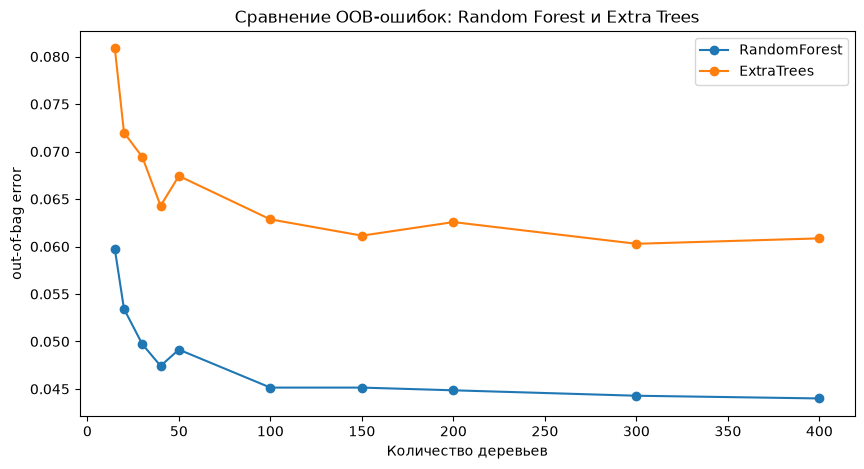

In [13]:
# Сравнительный график
ax = oob_df.plot(marker='o', figsize=(10, 5))
ax.set(ylabel='out-of-bag error', xlabel='Количество деревьев',
       title='Сравнение OOB-ошибок: Random Forest и Extra Trees')
plt.show()

Модель «случайного леса» демонстрирует стабильно более высокую эффективность по сравнению с моделью «дополнительных рандомизированных деревьев».

## Вопрос 5

* Выберите одну из моделей, демонстрирующих хорошие результаты, и рассчитайте показатели ошибок и матрицу путаницы на тестовом наборе данных.
* Учитывая распределение предсказанных классов, какой показатель является наиболее важным? А какой может вводить в заблуждение?


> Выбираем случайный лес со 150 деревьями (там ошибка уже стабилизировалась) и проверяем его на тестовых данных, которые он ещё не видел. Метрики:
> - **accuracy** - доля верных ответов (может вводить в заблуждение: если 85% клиентов остаются, то «все остаются» уже даёт 85%);
> - **precision** - из тех, кого модель назвала «уйдёт», сколько действительно ушло;
> - **recall** - из всех, кто реально ушёл, скольких модель нашла;
> - **F1** - среднее между precision и recall;
> - **ROC AUC** -насколько хорошо модель в целом отделяет один класс от другого.
>
> **Матрица путаницы** показывает 4 числа: верно угаданные «остался» / «ушёл» и два вида ошибок.

In [14]:
# Обучаем итоговую модель со 150 деревьями
model = RandomForestClassifier(n_estimators=150, oob_score=True, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Предсказания на тестовых данных
y_pred = model.predict(X_test)                 # предсказанные классы
y_prob = model.predict_proba(X_test)[:, 1]     # вероятность класса "ушёл" (True)

# Основной отчёт по метрикам
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       False       0.96      0.99      0.98      1288
        True       0.95      0.76      0.85       212

    accuracy                           0.96      1500
   macro avg       0.95      0.88      0.91      1500
weighted avg       0.96      0.96      0.96      1500



In [15]:
# Сводная таблица метрик
score_df = pd.DataFrame({
    'accuracy':  [accuracy_score(y_test, y_pred)],
    'precision': [precision_score(y_test, y_pred)],
    'recall':    [recall_score(y_test, y_pred)],
    'f1':        [f1_score(y_test, y_pred)],
    'auc':       [roc_auc_score(y_test, y_prob)]
}, index=['RandomForest']).round(3)

score_df

,accuracy,precision,recall,f1,auc
RandomForest,0.961,0.947,0.764,0.846,0.923


Неудивительно, что показатель воспроизведения для класса «Ушедшие клиенты» (True) довольно низкий, поскольку их количество весьма невелико. Тем не менее, мы показываем лучшие результаты, чем при случайном угадывании: точность составляет 0,932 (против 0,85 при случайном угадывании).

In [16]:
# Для сравнения: точность, если всегда отвечать самым частым классом
baseline = y_test.value_counts(normalize=True).max()
print('Точность "угадывания" самым частым классом:', round(baseline, 3))
print('Точность модели:', round(accuracy_score(y_test, y_pred), 3))

Точность "угадывания" самым частым классом: 0.859
Точность модели: 0.961


## Вопрос 6

* Распечатайте или отобразите матрицу путаницы.
* Постройте кривые ROC-AUC и точность-воспроизводимость.
* Постройте график важности признаков.


> - **Матрица путаницы** - таблица: по строкам реальные классы, по столбцам предсказанные.
> - **ROC-кривая** показывает долю найденных ушедших клиентов (TPR) против доли ложных тревог (FPR) при разных порогах вероятности. Чем выше кривая к левому верхнему углу, тем лучше.
> - **Кривая precision–recall** полезна при несбалансированных классах: показывает компромисс между точностью и полнотой.
> - **Важность признаков** (`feature_importances_`) говорит, какие признаки сильнее всего влияли на решения леса.

[[1279    9]
 [  50  162]]


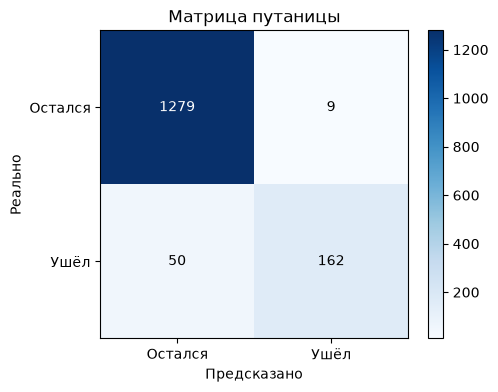

In [17]:
# Матрица путаницы (числа)
cm = confusion_matrix(y_test, y_pred)
print(cm)

# Красивая версия матрицы
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(['Остался', 'Ушёл']); ax.set_yticklabels(['Остался', 'Ушёл'])
ax.set_xlabel('Предсказано'); ax.set_ylabel('Реально')
ax.set_title('Матрица путаницы')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.colorbar(im)
plt.show()

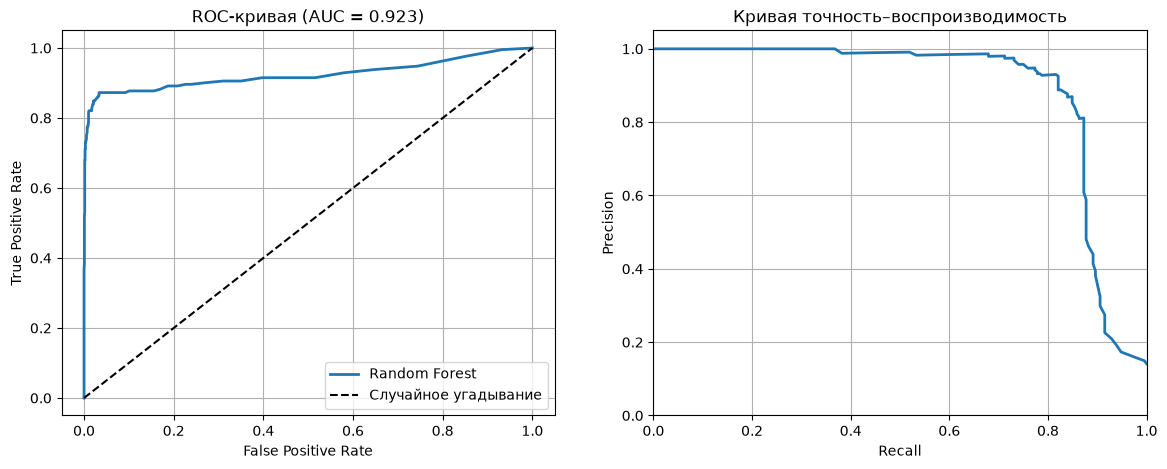

In [18]:
# Данные для кривых
fpr, tpr, _ = roc_curve(y_test, y_prob)
precision, recall, _ = precision_recall_curve(y_test, y_prob)

fig, axList = plt.subplots(ncols=2, figsize=(14, 5))

# ROC-кривая
axList[0].plot(fpr, tpr, linewidth=2, label='Random Forest')
axList[0].plot([0, 1], [0, 1], 'k--', label='Случайное угадывание')
axList[0].set(xlabel='False Positive Rate', ylabel='True Positive Rate',
              title='ROC-кривая (AUC = {:.3f})'.format(roc_auc_score(y_test, y_prob)))
axList[0].legend()
axList[0].grid()

# Кривая precision-recall
axList[1].plot(recall, precision, linewidth=2)
axList[1].set(xlabel='Recall', ylabel='Precision', title='Кривая точность–воспроизводимость',
              xlim=(0, 1), ylim=(0, 1.05))
axList[1].grid()

plt.show()

Кривые ROC-AUC и «точность-охватываемость».

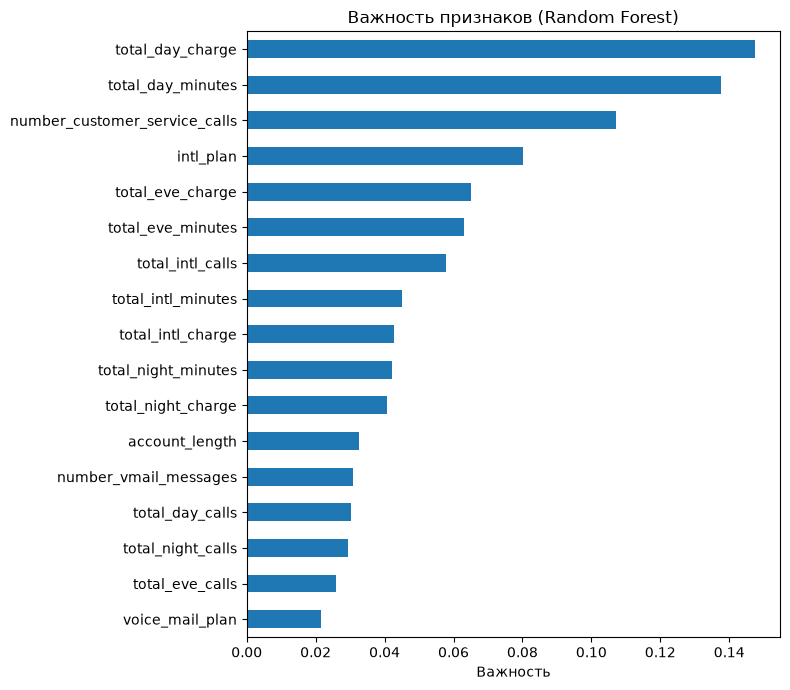

total_day_charge                 0.147362
total_day_minutes                0.137497
number_customer_service_calls    0.107139
intl_plan                        0.080264
total_eve_charge                 0.065041
dtype: float64

In [19]:
# Важность признаков: сортируем по убыванию
feature_imp = pd.Series(model.feature_importances_, index=feature_cols).sort_values()

ax = feature_imp.plot(kind='barh', figsize=(8, 7))
ax.set(xlabel='Важность', title='Важность признаков (Random Forest)')
plt.tight_layout()
plt.show()

# Топ-5 самых важных признаков
feature_imp.sort_values(ascending=False).head(5)

Важность признаков. Общая ежедневная стоимость является наиболее значимым предиктором оттока клиентов.